<a href="https://colab.research.google.com/github/axelvazquezp/RappiPlus_Data_Driven_Decisions/blob/main/Proyecto_Final_rappiplus.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Proyecto RappiPlus: de datos a decisiones de negocio

**Introducción**


El objetivo de este proyecto es evaluar el desempeño del servicio **RappiPlus** para apoyar **decisiones de negocio basadas en datos**.

Se trabajan con múltiples datasets del negocio:

- **rappiplus_orders_raw.csv** → información de pedidos, precios, descuentos y revenue  
- **rappiplus_catalog.csv** → costos de productos, categorías y proveedores  
- **rappiplus_marketing_spend.csv** → inversión en marketing por canal y país  
- **events / users / user_activity (SQL)** → comportamiento del usuario dentro de la plataforma  
- **experiment_checkout_ui.csv** → resultados de un experimento A/B en el checkout  

El análisis sigue una lógica clara y progresiva:

1. 🔍 Evaluar si podemos confiar en los datos (calidad de datos en Python)

2. 💰 Analizar si el negocio es rentable (revenue, costos y profit)  

3. 🛒 Entender dónde se pierden los usuarios (funnel de conversión)  

4. 🔁 Evaluar si los usuarios regresan (retención por cohortes)  

5. 🧪 Validar si los cambios generan impacto (test estadístico)  

6. 📊 Comunicar los resultados (dashboard en BI)  

A lo largo del proyecto, se transforman datos en insights para responder preguntas clave del negocio y proponer **recomendaciones accionables**.

---

## 🔹 Paso 1: Cargar y validar la calidad de los datos

---

### 1.1 Carga de datos y vista rápida

**🎯 Objetivo:** Familiarizarte con la estructura de los datasets del negocio antes de analizarlos.

**Instrucciones:**

- Importa las librerías necesarias
- Carga los archivos:
  - `rappiplus_orders_raw.csv`
  - `rappiplus_catalog.csv`
  - `rappiplus_marketing_spend.csv`
- Guarda los DataFrames en:
  - `orders`, `catalog`, `marketing`
- Explora cada dataset.

---

In [ ]:
# importar librerías
# Imports básicos
import pandas as pd
import numpy as np

# Visualización
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
# cargar archivos
orders = pd.read_csv('https://practicum-content.s3.amazonaws.com/datasets/rappiplus_orders_raw.csv')
catalog = pd.read_csv('https://practicum-content.s3.amazonaws.com/datasets/rappiplus_catalog.csv')
marketing = pd.read_csv('https://practicum-content.s3.amazonaws.com/datasets/rappiplus_marketing_spend.csv')

In [ ]:
# explorar datasets
# tu código aquí

In [ ]:
print("--- DATASET ORDERS ---")
print (orders.head(3))
print("--- DATASET CATALOG ---")
print (catalog.head(7))
print("--- DATASET MARKETING ---")
print (marketing.head(3))

--- DATASET ORDERS ---
  id_pedido id_usuario fecha_hora_pedido       pais dispositivo  \
0   order_0  user_6993        2025-05-22  Argentina     desktop   
1   order_1  user_1329        2025-06-15     Mexico     desktop   
2   order_2  user_3194        2025-05-02  Argentina     desktop   

  fuente_referencia       nombre_producto categoria_producto  cantidad  \
0           organic       Jacket-Winter-M               Moda       2.0   
1       paid_search  Tablet-Standard-64GB        Electronica       1.0   
2            social        Blender-XL-Red              Hogar       2.0   

   precio_unitario  monto_descuento  monto_total  
0           332.69              0.0       665.37  
1           176.86              5.0       171.86  
2           102.99             10.0       195.99  
--- DATASET CATALOG ---
        nombre_producto categoria_producto  costo_unitario  \
0    Laptop-Gaming-16GB        Electrónica          280.68   
1       Phone-Pro-128GB        Electrónica           10.12 

In [ ]:
print("--- DATASET ORDERS---")
print (orders.info())
print()
print("--- DATASET CATALOG ---")
print (catalog.info())
print()
print("--- DATASET MARKETING ---")
print (marketing.info())

--- DATASET ORDERS---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 25100 entries, 0 to 25099
Data columns (total 12 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   id_pedido           25100 non-null  object 
 1   id_usuario          25100 non-null  object 
 2   fecha_hora_pedido   25100 non-null  object 
 3   pais                24800 non-null  object 
 4   dispositivo         25080 non-null  object 
 5   fuente_referencia   25070 non-null  object 
 6   nombre_producto     25070 non-null  object 
 7   categoria_producto  25020 non-null  object 
 8   cantidad            25050 non-null  float64
 9   precio_unitario     25050 non-null  float64
 10  monto_descuento     25050 non-null  float64
 11  monto_total         25100 non-null  float64
dtypes: float64(4), object(8)
memory usage: 2.3+ MB
None

--- DATASET CATALOG ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7 entries, 0 to 6
Data columns (total 4 columns):
 

Unicamente la tabla orders necesita cambio de formato en la columna 'fecha_orden_pedido', asi como analizar los casos de valores nulos, la tabla de marketing tiene cerca de 100 valores nulos en la columna 'canal' yo sugiero manejar estos valores como nulos o 'desconocido'

In [ ]:
print("--- DATASET ORDERS ---")
print (orders.describe())
print()
print("--- DATASET CATALOG ---")
print (catalog.describe())
print()
print("--- DATASET MARKETING ---")
print (marketing.describe())

--- DATASET ORDERS ---
           cantidad  precio_unitario  monto_descuento   monto_total
count  25050.000000     25050.000000     25050.000000  2.510000e+04
mean       7.092735       259.305549         4.500798  2.072680e+03
std      296.277003       138.726461         5.223010  9.894995e+04
min       -2.000000        20.030000         0.000000 -4.926500e+02
25%        1.000000       138.377500         0.000000  1.805075e+02
50%        2.000000       258.715000         0.000000  3.417500e+02
75%        2.000000       380.332500        10.000000  5.185800e+02
max    20000.000000       499.960000        15.000000  8.840200e+06

--- DATASET CATALOG ---
       costo_unitario
count        7.000000
mean       102.252857
std        111.011563
min         10.120000
25%         16.905000
50%         25.210000
75%        182.975000
max        280.680000

--- DATASET MARKETING ---
            gasto
count  1620.00000
mean   1772.74292
std     734.43294
min     501.11000
25%    1128.03000
50%    

### Revisión y calidad de datos

**🎯 Objetivo:** Detectar y corregir problemas en los datos que puedan afectar el análisis de revenue, costos y rentabilidad.

Se revisan los 3 datasets
- Validar y convertir fechas al formato correcto  
- Revisar variables numéricas (sin negativos o ceros inválidos)  
- Verificar consistencia de montos  
- Eliminar duplicados  
- Revisar variables categóricas

---

In [ ]:
#Convertir las columnas a tipo fecha
orders['fecha_hora_pedido'] = pd.to_datetime(orders['fecha_hora_pedido'], utc=True, errors='coerce')
orders.info()
print()
marketing['fecha'] = pd.to_datetime(marketing['fecha'], utc=True, errors='coerce')
marketing.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 25100 entries, 0 to 25099
Data columns (total 12 columns):
 #   Column              Non-Null Count  Dtype              
---  ------              --------------  -----              
 0   id_pedido           25100 non-null  object             
 1   id_usuario          25100 non-null  object             
 2   fecha_hora_pedido   25100 non-null  datetime64[ns, UTC]
 3   pais                24800 non-null  object             
 4   dispositivo         25080 non-null  object             
 5   fuente_referencia   25070 non-null  object             
 6   nombre_producto     25070 non-null  object             
 7   categoria_producto  25020 non-null  object             
 8   cantidad            25050 non-null  float64            
 9   precio_unitario     25050 non-null  float64            
 10  monto_descuento     25050 non-null  float64            
 11  monto_total         25100 non-null  float64            
dtypes: datetime64[ns, UTC](1), float

In [ ]:
#Se corrige la tilde para que no haya discrepancia con la tabla catalog
orders['categoria_producto'] = orders['categoria_producto'].str.replace('Electronica', 'Electrónica', case=False)
orders['categoria_producto'].unique()

array(['Moda', 'Electrónica', 'Hogar', nan], dtype=object)

In [ ]:
#Revisar variables numericas
errores = orders[(orders['cantidad'] <= 0) | (orders['monto_total'] <= 0)]
print (errores)

     id_pedido id_usuario         fecha_hora_pedido pais dispositivo  \
266  order_266  user_7011 2025-03-13 00:00:00+00:00  NaN     desktop   
267  order_267  user_1087 2025-05-07 00:00:00+00:00  NaN     desktop   
268  order_268    user_84 2025-02-19 00:00:00+00:00  NaN     desktop   
269  order_269  user_3323 2025-05-25 00:00:00+00:00  NaN     desktop   

    fuente_referencia  nombre_producto categoria_producto  cantidad  \
266       paid_search  Phone-Pro-128GB        Electrónica      -2.0   
267            social  Phone-Pro-128GB        Electrónica      -1.0   
268           organic  Phone-Pro-128GB        Electrónica      -1.0   
269       paid_search  Phone-Pro-128GB        Electrónica      -1.0   

     precio_unitario  monto_descuento  monto_total  
266           101.31             10.0      -192.62  
267            43.50              5.0       -38.50  
268           497.65              5.0      -492.65  
269           423.53              0.0      -423.53  


In [ ]:
#Se eliminan los valores imposibles
orders = orders[(orders['cantidad'] > 0) & (orders['monto_total'] > 0)]

orders.describe()

,cantidad,precio_unitario,monto_descuento,monto_total
count,25046.000000,25046.000000,25046.000000,2.504600e+04
mean,7.094067,259.304400,4.500719,2.076331e+03
std,296.300643,138.715188,5.223232,9.905653e+04
min,1.000000,20.030000,0.000000,5.240000e+00
25%,1.000000,138.405000,0.000000,1.804025e+02
50%,2.000000,258.715000,0.000000,3.415600e+02
75%,2.000000,380.272500,10.000000,5.184375e+02
max,20000.000000,499.960000,15.000000,8.840200e+06


In [ ]:
#Verificar consistencia de montos
orders['monto_calculado'] = (orders['cantidad'] * orders['precio_unitario'] - orders['monto_descuento']).round(2)
orders['monto_total'] = orders['monto_total'].round(2)

inconsistencias = orders[orders['monto_calculado'] != orders['monto_total']]

print(f"Se encontraron {len(inconsistencias)} registros con montos inconsistentes.")

Se encontraron 6256 registros con montos inconsistentes.


In [ ]:
inconsistencias[['cantidad', 'precio_unitario', 'monto_descuento', 'monto_calculado', 'monto_total']].head(10)

,cantidad,precio_unitario,monto_descuento,monto_calculado,monto_total
0,2.0,332.69,0.0,665.38,665.37
2,2.0,102.99,10.0,195.98,195.99
6,2.0,163.59,0.0,327.18,327.19
7,2.0,373.68,0.0,747.36,747.35
18,2.0,180.64,5.0,356.28,356.27
20,2.0,489.11,10.0,968.22,968.23
21,2.0,203.26,0.0,406.52,406.51
23,2.0,487.85,5.0,970.70,970.71
24,2.0,117.99,0.0,235.98,235.99
35,2.0,467.34,5.0,929.68,929.69


In [ ]:
diferencia = (orders['monto_calculado'] - orders['monto_total']).abs()
sospechosos = orders[diferencia > 0.02]

sospechosos[['cantidad', 'precio_unitario', 'monto_descuento', 'monto_calculado', 'monto_total']].head(10)

,cantidad,precio_unitario,monto_descuento,monto_calculado,monto_total


In [ ]:
#Eliminar duplicados
cantidad_copias = orders.duplicated(subset=['id_pedido']).sum()
cantidad_copias

100

In [ ]:
ordenes_duplicadas = orders[orders.duplicated(subset=['id_pedido'], keep=False)]
ordenes_duplicadas.sort_values(by='id_pedido')

,id_pedido,id_usuario,fecha_hora_pedido,pais,dispositivo,fuente_referencia,nombre_producto,categoria_producto,cantidad,precio_unitario,monto_descuento,monto_total,monto_calculado
25023,order_10082,user_690,2025-02-17 00:00:00+00:00,Argentina,desktop,social,Sneakers-Urban-42,Moda,2.0,221.34,0.0,442.67,442.68
10082,order_10082,user_690,2025-02-17 00:00:00+00:00,Argentina,desktop,social,Sneakers-Urban-42,Moda,2.0,221.34,0.0,442.67,442.68
25037,order_10709,user_6783,2025-02-16 00:00:00+00:00,Colombia,mobile,organic,Jacket-Winter-M,Moda,1.0,170.10,10.0,160.10,160.10
10709,order_10709,user_6783,2025-02-16 00:00:00+00:00,Colombia,mobile,organic,Jacket-Winter-M,Moda,1.0,170.10,10.0,160.10,160.10
25065,order_10829,user_7697,2025-01-23 00:00:00+00:00,Argentina,mobile,social,Phone-Pro-128GB,Electrónica,2.0,115.54,0.0,231.08,231.08
...,...,...,...,...,...,...,...,...,...,...,...,...,...
25048,order_8326,user_6177,2025-06-14 00:00:00+00:00,Argentina,mobile,organic,Vacuum-Pro-Black,Hogar,1.0,457.53,0.0,457.53,457.53
25043,order_8414,user_4073,2025-05-10 00:00:00+00:00,Colombia,mobile,social,Jacket-Winter-M,Moda,2.0,144.35,10.0,278.71,278.70
8414,order_8414,user_4073,2025-05-10 00:00:00+00:00,Colombia,mobile,social,Jacket-Winter-M,Moda,2.0,144.35,10.0,278.71,278.70
25056,order_974,user_3262,2025-05-04 00:00:00+00:00,Argentina,desktop,paid_search,Blender-XL-Red,Hogar,2.0,268.58,5.0,532.16,532.16


In [ ]:
orders = orders.drop_duplicates(subset=['id_pedido'], keep='first')
orders.duplicated(subset=['id_pedido']).sum()

0

In [ ]:
#Revisar variables categoricas
def col_categoricas(df, nombre):
    columnas = df.select_dtypes(include=['object', 'category']).columns.tolist()
    print(f"Columnas categóricas de {nombre}: {columnas}")
    return columnas

cat_orders = col_categoricas(orders, "orders")
cat_catalog = col_categoricas(catalog, "catalog")
cat_marketing = col_categoricas(marketing, "marketing")

Columnas categóricas de orders: ['id_pedido', 'id_usuario', 'pais', 'dispositivo', 'fuente_referencia', 'nombre_producto', 'categoria_producto']
Columnas categóricas de catalog: ['nombre_producto', 'categoria_producto', 'proveedor']
Columnas categóricas de marketing: ['pais', 'id_campaña', 'canal']


In [ ]:
cat_orders = ['pais', 'dispositivo', 'fuente_referencia', 'nombre_producto', 'categoria_producto']
for col in cat_orders:
    print(orders[col].unique())
    print(orders[col].value_counts())
    print()

['Argentina' 'Mexico' 'Colombia' 'mexico' 'colombia' nan 'argentina']
Colombia     7467
Mexico       7465
Argentina    7239
mexico        862
colombia      822
argentina     795
Name: pais, dtype: int64

['desktop' 'mobile' nan]
desktop    12681
mobile     12245
Name: dispositivo, dtype: int64

['organic' 'paid_search' 'social' nan]
social         8385
organic        8269
paid_search    8262
Name: fuente_referencia, dtype: int64

['Jacket-Winter-M' 'Tablet-Standard-64GB' 'Blender-XL-Red'
 'Laptop-Gaming-16GB' 'Sneakers-Urban-42' 'Phone-Pro-128GB'
 'Vacuum-Pro-Black' nan]
Blender-XL-Red          4176
Vacuum-Pro-Black        4170
Jacket-Winter-M         4166
Sneakers-Urban-42       4129
Laptop-Gaming-16GB      2778
Tablet-Standard-64GB    2764
Phone-Pro-128GB         2733
Name: nombre_producto, dtype: int64

['Moda' 'Electrónica' 'Hogar' nan]
Hogar          8346
Moda           8295
Electrónica    8275
Name: categoria_producto, dtype: int64



In [ ]:
#Estandarizacion de los paises
orders['pais'] = orders['pais'].str.strip().str.title()
orders['pais'].unique()

array(['Argentina', 'Mexico', 'Colombia', nan], dtype=object)

In [ ]:
cat_catalog = ['nombre_producto', 'categoria_producto', 'proveedor']
for col in cat_catalog:
    print(catalog[col].unique())
    print(catalog[col].value_counts())
    print()

['Laptop-Gaming-16GB' 'Phone-Pro-128GB' 'Tablet-Standard-64GB'
 'Blender-XL-Red' 'Vacuum-Pro-Black' 'Sneakers-Urban-42' 'Jacket-Winter-M']
Laptop-Gaming-16GB      1
Jacket-Winter-M         1
Blender-XL-Red          1
Tablet-Standard-64GB    1
Phone-Pro-128GB         1
Vacuum-Pro-Black        1
Sneakers-Urban-42       1
Name: nombre_producto, dtype: int64

['Electrónica' 'Hogar' 'Moda']
Electrónica    3
Hogar          2
Moda           2
Name: categoria_producto, dtype: int64

['Fuller, Pena and Myers' 'King Ltd' 'Bowers LLC' 'Long-Reid'
 'Rivera, Carr and Finley' 'Greene-Smith' 'Mcmillan-Rhodes']
Rivera, Carr and Finley    1
Fuller, Pena and Myers     1
Mcmillan-Rhodes            1
Long-Reid                  1
Bowers LLC                 1
King Ltd                   1
Greene-Smith               1
Name: proveedor, dtype: int64



In [ ]:
cat_marketing = ['pais', 'id_campaña', 'canal']
for col in cat_marketing:
    print(marketing[col].unique())
    print(marketing[col].value_counts())
    print()

['Mexico' 'Colombia' 'Argentina']
Argentina    540
Colombia     540
Mexico       540
Name: pais, dtype: int64

['organic_Mexico' 'paid_search_Mexico' 'social_Mexico' 'organic_Colombia'
 'paid_search_Colombia' 'social_Colombia' 'organic_Argentina'
 'paid_search_Argentina' 'social_Argentina']
social_Colombia          180
organic_Argentina        180
organic_Mexico           180
organic_Colombia         180
social_Argentina         180
paid_search_Mexico       180
paid_search_Colombia     180
social_Mexico            180
paid_search_Argentina    180
Name: id_campaña, dtype: int64

['organic' 'paid_search' 'social' nan]
paid_search    507
organic        506
social         506
Name: canal, dtype: int64



In [ ]:
# Contar nulos por columna y porcentaje
nulos_orders = pd.DataFrame({
    'nulos' : orders.isna().sum(),
    'porcentaje' : orders.isna().mean() * 100
}).sort_values('nulos', ascending=False)

nulos_orders

,nulos,porcentaje
pais,296,1.186563
fuente_referencia,30,0.120260
nombre_producto,30,0.120260
categoria_producto,30,0.120260
dispositivo,20,0.080173
id_pedido,0,0.000000
id_usuario,0,0.000000
fecha_hora_pedido,0,0.000000
cantidad,0,0.000000
precio_unitario,0,0.000000


Se imputaran todos los valores vacios con "desconocido"

In [ ]:
orders[['pais', 'fuente_referencia', 'nombre_producto', 'categoria_producto', 'dispositivo']] = orders[['pais', 'fuente_referencia', 'nombre_producto', 'categoria_producto', 'dispositivo']].fillna('desconocido')
orders.isna().sum()

id_pedido             0
id_usuario            0
fecha_hora_pedido     0
pais                  0
dispositivo           0
fuente_referencia     0
nombre_producto       0
categoria_producto    0
cantidad              0
precio_unitario       0
monto_descuento       0
monto_total           0
monto_calculado       0
dtype: int64

In [ ]:
nulos_marketing = pd.DataFrame({
    'nulos' : marketing.isna().sum(),
    'porcentaje' : marketing.isna().mean() * 100
}).sort_values('nulos', ascending=False)

nulos_marketing

,nulos,porcentaje
canal,101,6.234568
fecha,0,0.000000
pais,0,0.000000
id_campaña,0,0.000000
gasto,0,0.000000


Como es mas del 5% se imputara como "desconocido".

In [ ]:


marketing['canal'] = marketing['canal'].fillna('desconocido')
marketing.isna().sum()



fecha         0
pais          0
id_campaña    0
canal         0
gasto         0
dtype: int64

---
**📦 Exportación**: Una vez finalizada la limpieza, se exportan los datasets para utilizarlos en la última etapa del proyecto.

In [ ]:
# exportar datasets
orders.to_csv('orders_clean.csv', index=False)
catalog.to_csv('catalog_clean.csv', index=False)
marketing.to_csv('marketing_clean.csv', index=False)

---

## 🔹 Paso 2: Analizar si el negocio es rentable

### 2.1 Cálculo de KPIs principales

**🎯 Objetivo:** Calcular los indicadores clave del negocio para evaluar ingresos, costos y rentabilidad.

Se usan los 3 datasets (`orders`, `catalog`, `marketing_spend`):

**📊 Parte 1: Rentabilidad del negocio**
- ¿Cuál es el ingreso total (revenue)?
- ¿Cuál es el costo total?
- ¿Cuánto se ha invertido en marketing?
- ¿El negocio es rentable? (calcular profit)  

---

**📈 Parte 2: Comportamiento de ventas**
- ¿Cuál es el ticket promedio por orden?
- ¿Cuál es la cantidad promedio de productos por orden?
- ¿Cuál es el producto más vendido?
- ¿Cuánto se ha gastado en marketing por canal?

In [ ]:
# Ingreso total (revenue)
revenue = orders['monto_total'].sum()
print (f'El ingreso total es : ${revenue:,.2f}')

El ingreso total es : $51,966,981.56


In [ ]:
#Costo total
orders_costo = orders.merge(catalog[['nombre_producto', 'costo_unitario']], on='nombre_producto', how='left')

orders_costo['costo_linea'] = orders_costo['cantidad'] * orders_costo['costo_unitario']
costo_total = orders_costo['costo_linea'].sum()
print (f'El costo total es : ${costo_total:,.2f}')

El costo total es : $43,124,069.01


In [ ]:

MARGEN_BRUTO = (revenue - costo_total)*100/ revenue
print (f'El margen bruto : %{MARGEN_BRUTO:,.2f}')


El margen bruto : %17.02


In [ ]:
#Inversion en marketing
marketing_total = marketing['gasto'].sum()
print (f'La inversion total en marketing es : ${marketing_total:,.2f}')

La inversion total en marketing es : $2,871,843.53


In [ ]:
#Profit o ganancia neta
profit = revenue - costo_total - marketing_total
es_rentable = profit > 0

print (f'El profit es : ${profit:,.2f}')
print(f"¿El negocio es rentable?: {'SÍ' if es_rentable else 'NO'}")

El profit es : $5,971,069.02
¿El negocio es rentable?: SÍ


In [ ]:
ROI = (profit / (costo_total + marketing_total)) * 100
print (f'ROI : %{ROI:,.2f}')

ROI : %12.98


In [ ]:
ROMI = (profit/ (marketing_total)) * 100
print (f'ROMI : %{ROMI:,.2f}')

ROMI : %207.92


In [ ]:
#Ticket promedio por orden
ticket_promedio = orders['monto_total'].mean()
print (f'El ticket promedio es : ${ticket_promedio:,.2f}')

El ticket promedio es : $2,083.18


In [ ]:
#Cantidad de productos promedios por orden
productos_por_orden = orders['cantidad'].mean()
print (f'La cantidad de productos promedio por orden es : {productos_por_orden:,.0f}')

La cantidad de productos promedio por orden es : 7


In [ ]:
#Producto mas vendido
producto_estrella = orders.groupby('nombre_producto')['monto_total'].sum().idxmax()
print (producto_estrella)

Laptop-Gaming-16GB


In [ ]:
#Gasto en marketing por canal
gasto_por_canal = marketing.groupby('canal')['gasto'].sum().sort_values(ascending=False)
print (gasto_por_canal)

canal
social         918043.21
organic        913533.01
paid_search    863088.21
desconocido    177179.10
Name: gasto, dtype: float64


---

## 🔹 Paso 3: Entender dónde se pierden los usuarios (funnel de conversión)

**🎯 Objetivo:** Analizar el comportamiento de los usuarios para identificar en qué etapa del proceso se pierden.


⚙️**Conexión a la base de datos**:  
Se ejecuta la línea de configuración para conectar con la base de datos y aplicar consultas SQL en la tabla **events**.

---

**📊 Parte 1: Construcción del funnel**
- ¿Cuántos usuarios llegan a cada etapa del funnel?  
- Se calcula el número de usuarios únicos por `nombre_evento`  
- Se ordenan los eventos según el flujo del usuario  

---

**📉 Parte 2: Análisis de conversión**
- Se calcula la tasa de conversión entre cada paso del funnel  
- Se identifica en qué etapa se pierde la mayor cantidad de usuarios  
- ¿Cuál es la tasa de conversión final?
---

In [ ]:
import pandas as pd
from sqlalchemy import create_engine

# ======================
# Conexión (NO modificar)
# ======================
db_config = {
    'user': 'practicum_student',
    'pwd': 'QnmDH8Sc2TQLvy2G3Vvh7',
    'host': 'yp-trainers-practicum.cluster-czs0gxyx2d8w.us-east-1.rds.amazonaws.com',
    'port': 5432,
    'db': 'data-analyst-production-db-en'
}

connection_string = 'postgresql://{}:{}@{}:{}/{}'.format(
    db_config['user'],
    db_config['pwd'],
    db_config['host'],
    db_config['port'],
    db_config['db']
)

engine = create_engine(connection_string, connect_args={'sslmode':'require'})

In [ ]:
# Explorar tabla events
# =========================
query_events = '''
SELECT *
FROM events;
'''
events = pd.read_sql(query_events, con=engine)
events.head()

,id_usuario,id_sesion,nombre_evento,timestamp_evento,pais,dispositivo,fuente_referencia,categoria_producto
0,user_6772,6a97f2af-32ae-4186-8c92-04025be1a27b,first_visit,2025-05-17,Colombia,desktop,organic,Moda
1,user_5883,369b767c-1c33-4b2f-a652-c7c0ef92cfc9,add_to_cart,2025-02-23,Mexico,mobile,social,Hogar
2,user_5946,60039041-e78b-474c-87b3-c0b7e9c30708,add_payment_info,2025-05-15,Colombia,desktop,social,Electronica
3,user_827,18252a64-f389-4ef7-9e58-dadad4a3491e,purchase,2025-03-31,Mexico,mobile,social,Moda
4,user_2361,221b364e-cdc5-4668-b698-18d5ba849a67,first_visit,2025-01-22,Argentina,desktop,paid_search,Electronica


In [ ]:
# PARTE 1: Totales del funnel
# ======================
query_totals = '''
SELECT
    COUNT (DISTINCT CASE WHEN nombre_evento = 'first_visit' THEN id_usuario END) AS first_visit,
    COUNT (DISTINCT CASE WHEN nombre_evento = 'select_item' AND id_usuario IN (SELECT id_usuario FROM events WHERE nombre_evento = 'first_visit') THEN id_usuario END) AS select_item,
    COUNT (DISTINCT CASE WHEN nombre_evento = 'add_to_cart' AND id_usuario IN (SELECT id_usuario FROM events WHERE nombre_evento = 'select_item')THEN id_usuario END) AS add_to_cart,
    COUNT (DISTINCT CASE WHEN nombre_evento = 'begin_checkout' AND id_usuario IN (SELECT id_usuario FROM events WHERE nombre_evento = 'add_to_cart') THEN id_usuario END) AS begin_checkout,
    COUNT (DISTINCT CASE WHEN nombre_evento = 'add_payment_info' AND id_usuario IN (SELECT id_usuario FROM events WHERE nombre_evento = 'begin_checkout') THEN id_usuario END) AS add_payment,
    COUNT (DISTINCT CASE WHEN nombre_evento = 'purchase' AND id_usuario IN (SELECT id_usuario FROM events WHERE nombre_evento = 'add_payment_info') THEN id_usuario END) AS purchase
FROM events;
'''

totals = pd.read_sql(query_totals, con=engine)
print ('Usuarios que llegan a cada etapa')
totals

Usuarios que llegan a cada etapa


,first_visit,select_item,add_to_cart,begin_checkout,add_payment,purchase
0,7796,7393,7233,6887,5638,4858


In [ ]:
# PARTE 2: Conversiones
# ======================

query_conversion = '''
WITH funnel AS(
SELECT
    COUNT (DISTINCT CASE WHEN nombre_evento = 'first_visit' THEN id_usuario END) AS first_step,
    COUNT (DISTINCT CASE WHEN nombre_evento = 'select_item' AND id_usuario IN (SELECT id_usuario FROM events WHERE nombre_evento = 'first_visit') THEN id_usuario END) AS second_step,
    COUNT (DISTINCT CASE WHEN nombre_evento = 'add_to_cart' AND id_usuario IN (SELECT id_usuario FROM events WHERE nombre_evento = 'select_item')THEN id_usuario END) AS third_step,
    COUNT (DISTINCT CASE WHEN nombre_evento = 'begin_checkout' AND id_usuario IN (SELECT id_usuario FROM events WHERE nombre_evento = 'add_to_cart') THEN id_usuario END) AS fourth_step,
    COUNT (DISTINCT CASE WHEN nombre_evento = 'add_payment_info' AND id_usuario IN (SELECT id_usuario FROM events WHERE nombre_evento = 'begin_checkout') THEN id_usuario END) AS fifth_step,
    COUNT (DISTINCT CASE WHEN nombre_evento = 'purchase' AND id_usuario IN (SELECT id_usuario FROM events WHERE nombre_evento = 'add_payment_info') THEN id_usuario END) AS sixth_step
FROM events)
SELECT
    ROUND (second_step *1.0 / first_step,2) AS tasac1,
    ROUND (third_step *1.0 / second_step,2) AS tasac2,
    ROUND (fourth_step *1.0 / third_step,2) AS tasac3,
    ROUND (fifth_step *1.0 / fourth_step,2) AS tasac4,
    ROUND (sixth_step *1.0 / fifth_step,2) AS tasac5,
    ROUND (sixth_step *1.0 / first_step,2) AS tasa_conversion_final,
    first_step - second_step AS users_perdidos1,
    second_step - third_step AS users_perdidos2,
    third_step - fourth_step AS users_perdidos3,
    fourth_step - fifth_step AS users_perdidos4,
    fifth_step - sixth_step AS users_perdidos5
FROM funnel
'''
conversion = pd.read_sql(query_conversion, con=engine)
conversion

,tasac1,tasac2,tasac3,tasac4,tasac5,tasa_conversion_final,users_perdidos1,users_perdidos2,users_perdidos3,users_perdidos4,users_perdidos5
0,0.95,0.98,0.95,0.82,0.86,0.62,403,160,346,1249,780


La etapa en la que se pierden mas usuarios es al pasar de la etapa add_to_cart a begin_checkout con 1249 usuarios.

La tasa de conversion final es de un 62%.

## 🔹 Paso 4: Evaluar si los usuarios regresan (retención por cohortes)

**🎯 Objetivo:** Analizar la retención de usuarios para entender si regresan después de registrarse.

**Tablas**

- `users`
- `user_activity`

---
1. Se identifica la cohorte de cada usuario según el **mes de registro**.


2. Se calcula la retención semanal: cuántos usuarios **se mantienen activos** en cada semana desde su registro.
   - `retenido_w1`: usuarios activos en la semana 1  
   - `retenido_w2`: usuarios activos en la semana 2  
   - `retenido_w3`: usuarios activos en la semana 3  


3. Se calcula el porcentaje de retención para cada semana, dividiendo los usuarios retenidos entre los clientes iniciales de la cohorte:  
   - `semana_1`: porcentaje de usuarios retenidos en la semana 1  
   - `semana_2`: porcentaje de usuarios retenidos en la semana 2  
   - `semana_3`: porcentaje de usuarios retenidos en la semana 3  

Se revisa que la columna de fecha esté en formato correcto (`DATE`).  
Se realiza la conversión usando: `CAST(fecha_registro AS DATE)`

In [ ]:
# Explorar tabla users
# =========================
query_users = '''
SELECT *
FROM users;
'''
users = pd.read_sql(query_users, con=engine)
users.head(3)

,id_usuario,fecha_registro,país,dispositivo,tipo_plan
0,user_0,2025-01-29,Mexico,mobile,free
1,user_1,2025-01-07,Mexico,mobile,free
2,user_2,2025-03-12,Argentina,mobile,free


In [ ]:
# Explorar tabla user_activity
# =========================
query_user_activity = '''
SELECT *
FROM user_activity;
'''
user_activity = pd.read_sql(query_user_activity, con=engine)
user_activity.head(3)

,id_usuario,fecha_actividad,dias_despues_registro,activo
0,user_0,2025-02-05,7,0
1,user_0,2025-02-12,14,1
2,user_0,2025-02-19,21,1


In [ ]:
# Retención por cohortes
# ======================

query_cohort_retention_final = '''
WITH cohorte as (SELECT
  id_usuario,
  DATE_TRUNC ('month', CAST(fecha_registro AS DATE))::Date AS mescohorte
  FROM users
  ),
actividad_semanal AS (SELECT
    c.mescohorte,
    COUNT (DISTINCT c.id_usuario) AS usuarios_iniciales,
    COUNT (DISTINCT CASE WHEN a.dias_despues_registro >=7 AND a.activo = 1 THEN c.id_usuario END) AS retenido_w1,
    COUNT (DISTINCT CASE WHEN a.dias_despues_registro >=14 AND a.activo = 1 THEN c.id_usuario END) AS retenido_w2,
    COUNT (DISTINCT CASE WHEN a.dias_despues_registro >=21 AND a.activo = 1 THEN c.id_usuario END) AS retenido_w3
FROM cohorte c
JOIN user_activity a ON c.id_usuario = a.id_usuario
GROUP BY c.mescohorte
)
SELECT
    mescohorte,
    retenido_w1,
    retenido_w2,
    retenido_w3,
    ROUND (retenido_w1*1.0 / NULLIF (usuarios_iniciales,0),2) AS semana1,
    ROUND (retenido_w2*1.0 / NULLIF (usuarios_iniciales,0),2) AS semana2,
    ROUND (retenido_w3*1.0 / NULLIF (usuarios_iniciales,0),2) AS semana3
FROM actividad_semanal
'''
# Ejecutar la consulta
cohorte_final = pd.read_sql(query_cohort_retention_final, con=engine)
cohorte_final

,mescohorte,retenido_w1,retenido_w2,retenido_w3,semana1,semana2,semana3
0,2025-01-01,1381,1253,1027,0.85,0.77,0.63
1,2025-02-01,1255,1154,940,0.87,0.80,0.65
2,2025-03-01,1428,1306,1060,0.87,0.80,0.65
3,2025-04-01,1394,1261,1022,0.87,0.79,0.64
4,2025-05-01,1446,1321,1088,0.86,0.78,0.64


---

## 🔹 Paso 5: Validar si los cambios generan impacto (test estadístico)

🎯 **Objetivo:** Evaluar si la modificación en la UI del checkout impacta la **tasa de conversión de compra**.

---

1. **Analizar el dataset** `experiment_checkout_ui.csv` para identificar la métrica principal **conversion**.
   - La métrica **conversion** es 1 si el usuario completó la compra, 0 si no.    
2. **Plantear la hipótesis estadística**     
3. **Aplicar el test estadístico adecuado**
4. **Interpretar el resultado**  

---
Hipótesis estadística
   - **H₀ (Hipótesis nula):** No hay diferencia real entre los grupos; la tasa de conversión es la misma, y cualquier diferencia observada es ruido aleatorio.  p₁ = p₂
   - **H₁ (Hipótesis alternativa):** Sí hay una diferencia real en la tasa de conversión entre los grupos.  p₁ ≠ p₂
   
**Test estadístico:** Z Test  
**Nivel de significancia alpha:** • 0.05. Si el p-valor es menor a 0.05, rechazamos la hipótesis nula.


In [ ]:
# tu código aquí
experiment = pd.read_csv('https://practicum-content.s3.amazonaws.com/datasets/experiment_checkout_ui.csv')
experiment.head (3)

,id_usuario,variante,convirtio,dispositivo,pais,duracion_sesion,timestamp
0,exp_user_0,tratamiento,0,mobile,Argentina,114.41,2025-03-28
1,exp_user_1,tratamiento,0,desktop,Mexico,170.03,2025-01-15
2,exp_user_2,control,1,mobile,Colombia,140.21,2025-03-18


In [ ]:
resumen = experiment.groupby('variante')['convirtio'].agg(['sum', 'count'])
print(resumen)

             sum  count
variante               
control      779   4965
tratamiento  820   5035


In [ ]:

from statsmodels.stats.proportion import proportions_ztest

exitos = [779, 820]
totales = [4965, 5035]

stat, p_valor = proportions_ztest(count=exitos, nobs=totales)
print(stat, p_valor)


-0.8132782986429474 0.41605851639119995


El valor de P es mayor a 0.05 por lo cual no rechazamos la hipotesis nula. No hay diferencia real entre los grupos; la tasa de conversión es la misma, y cualquier diferencia observada es ruido aleatorio. p₁ = p₂

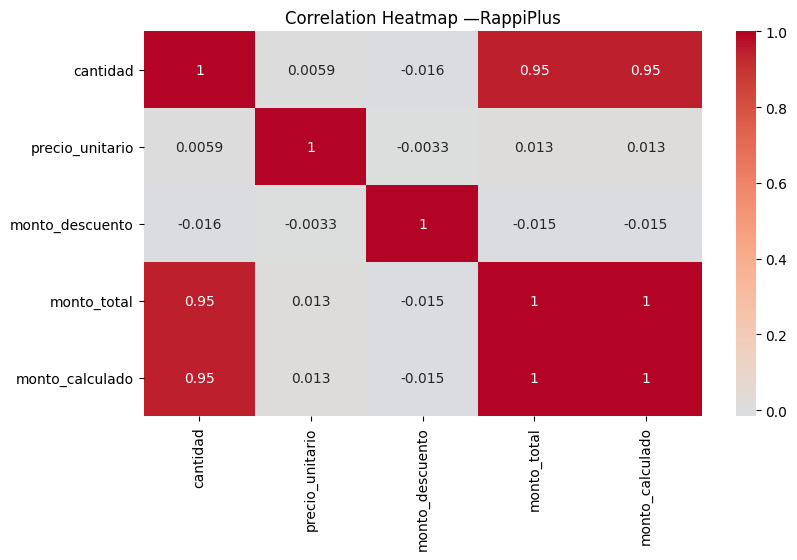

In [ ]:

orders_numericas = orders.select_dtypes(include='number')
corr = orders_numericas.corr()

plt.figure(figsize=(9,5))
sns.heatmap(corr, annot=True, cmap="coolwarm", center=0)
plt.title("Correlation Heatmap —RappiPlus")
plt.show()


No existe alguna correlacion importante.

---

## 🔹 Paso 6: Comunicar los resultados (Dashboard en BI)

🎯 **Objetivo**:  
Crear un dashboard que muestre de manera clara y visual los resultados del análisis de ventas, costos, marketing y conversión.

Se usarán los CSVs limpios del Paso 1:

- `orders_clean.csv`  
- `catalog_clean.csv`  
- `marketing_clean.csv`

---

1️⃣ Preparación de los datos
1. Cargar los CSVs en Power BI o Tableau.
2. Revisar relaciones:
   - `orders.nombre_producto` → `catalog.nombre_producto`
   - `orders.fecha_pedido` → tabla de fechas (crear calendario para análisis temporal)
   - `orders.fecha_pedido` → `dim_fecha.date`
3. Crear columnas calculadas necesarias
4. Crear tabla de fechas para poder calcular comparaciones YTD, YoY o períodos anteriores (`Previous Year`, `Previous Month`).

---

2️⃣ Dashboard 1: Overview Ejecutivo
**KPIs principales a mostrar:**
- Revenue total
- Profit total
- Gasto total en marketing
- Ticket promedio
- Cantidad promedio de productos por orden

**Visualizaciones sugeridas:**
- Tarjetas KPI para revenue, profit y gasto marketing
- Gráfico de líneas: evolución mensual de revenue o profit
- Gráfico de líneas YTD
- Gráfico de barras: revenue y profit por producto o categoría

---

 3️⃣ Dashboard 2: Detalle / Drill-through  
**Objetivo:** Permitir explorar los datos desde el KPI general hasta cada orden o producto.

**Visualizaciones sugeridas:**
- Tabla detallada de órdenes con:
  - producto, cantidad, revenue, cost, profit
  - color condicional (profit negativo en rojo, positivo en verde)
- Gráfico de barras por producto con medida `cantidad vendida`
- Drill-through: seleccionar un producto y ver todos los pedidos relacionados
- Filtros por fecha, categoría de producto, etc

---

## 🚀 Entrega Final


